In [1]:
import sys
sys.path.insert(0, "../src")
import numpy as np
import pandas as pd
import xarray as xr
import drought_events as de

pd.set_option("display.precision", 2)

z = np.array([0.5, -1.2, -1.5, -0.8, -1.1, np.nan, -2.0, -1.0, 0.3, -0.2, -1.3])
t = pd.date_range("2000-01-01", periods=z.size, freq="MS")
print(de.events(z, t))
print(de.summarise(xr.DataArray(z, dims="time", coords={"time": t})).to_series())

       start        end  duration  severity  intensity  peak
0 2000-02-01 2000-03-01         2       2.7       1.35  -1.5
1 2000-05-01 2000-05-01         1       1.1       1.10  -1.1
2 2000-07-01 2000-08-01         2       3.0       1.50  -2.0
3 2000-11-01 2000-11-01         1       1.3       1.30  -1.3
stat
n_events              4.00
events_per_decade    48.00
mean_duration         1.50
max_duration          2.00
mean_severity         2.03
max_severity          3.00
mean_intensity        1.31
pct_time             60.00
dtype: float64


In [2]:
proc = "../data/processed"
names = ["spi", "spei_th", "spei_hg"]
idx = xr.open_dataset(f"{proc}/marathwada_indices_025.nc")
idx = idx[names].sel(time=slice("1983-01", "2023-12"), scale=[3, 6, 12, 24])

stats = xr.Dataset({v: de.summarise(idx[v]) for v in names})
print(stats)

<xarray.Dataset> Size: 139kB
Dimensions:  (lat: 12, lon: 15, scale: 4, stat: 8)
Coordinates:
  * lat      (lat) float64 96B 17.75 18.0 18.25 18.5 ... 19.75 20.0 20.25 20.5
  * lon      (lon) float64 120B 74.75 75.0 75.25 75.5 ... 77.5 77.75 78.0 78.25
  * scale    (scale) int64 32B 3 6 12 24
  * stat     (stat) <U17 544B 'n_events' 'events_per_decade' ... 'pct_time'
Data variables:
    spi      (scale, lat, lon, stat) float64 46kB nan nan nan ... nan nan nan
    spei_th  (scale, lat, lon, stat) float64 46kB nan nan nan ... nan nan nan
    spei_hg  (scale, lat, lon, stat) float64 46kB nan nan nan ... nan nan nan


In [3]:
inside = idx["spi"].sel(scale=12).notnull().any("time")
w = np.cos(np.deg2rad(stats.lat)) * inside
tab = stats.weighted(w).mean(("lat", "lon")).to_array("index").to_series().unstack("stat")[de.STATS]
print(tab.round(2))

gaps = (idx.to_array("index").isnull() & inside).sum(("time", "lat", "lon")).to_series().unstack("scale")
print("Missing months inside Marathwada:\n", gaps)

halves = {"1983-2003": slice("1983", "2003"), "2004-2023": slice("2004", "2023")}
pct = xr.concat([xr.Dataset({v: de.summarise(idx[v].sel(time=p)).sel(stat="pct_time") for v in names})
                 for p in halves.values()], dim=pd.Index(list(halves), name="period"))
shift = (pct.sel(period="2004-2023") - pct.sel(period="1983-2003")).drop_vars("stat")
print("Change in % of months in drought, 2004-2023 minus 1983-2003:")
print(shift.weighted(w).mean(("lat", "lon")).to_dataframe().round(1))

stat           n_events  events_per_decade  mean_duration  max_duration  \
index   scale                                                             
spi     3         41.42              10.10           2.00          6.54   
        6         30.36               7.41           2.61          9.09   
        12        14.11               3.44           5.94         17.29   
        24        10.18               2.48           8.10         23.84   
spei_th 3         33.09               8.07           2.40          9.53   
        6         24.86               6.06           3.32         11.59   
        12        14.20               3.46           5.94         17.22   
        24        11.02               2.69           7.84         23.58   
spei_hg 3         37.42               9.13           2.27          7.86   
        6         28.17               6.87           3.07         10.85   
        12        14.51               3.54           5.93         17.53   
        24        10.93  

In [4]:
reg = pd.read_csv("../outputs/tables/marathwada_indices_regional.csv", index_col="time", parse_dates=True)
reg = reg.loc["1983-01":"2023-12"]
ev = []
for v in names:
    for k in [3, 12]:
        e = de.events(reg[f"{v}_{k}"].values, reg.index)
        e.insert(0, "scale", k)
        e.insert(0, "index", v)
        ev.append(e)
ev = pd.concat(ev, ignore_index=True)
for v in names:
    print(v, "12-month, five most severe:")
    print(ev[(ev["index"] == v) & (ev.scale == 12)].nlargest(5, "severity").drop(columns=["index", "scale"]).to_string(index=False))

dry = {v: reg[f"{v}_12"] <= -1 for v in names}
for v in ["spei_th", "spei_hg"]:
    both = (dry["spi"] & dry[v]).sum()
    print(f"SPI-12 drought months also in {v}-12: {both / dry['spi'].sum():.0%};  {v}-only months: {(dry[v] & ~dry['spi']).sum()}")

spi 12-month, five most severe:
     start        end  duration  severity  intensity  peak
2015-07-01 2016-06-01        12     18.80       1.57 -1.97
2012-07-01 2013-05-01        11     15.61       1.42 -2.08
2018-10-01 2019-08-01        11     14.97       1.36 -2.22
1991-10-01 1992-08-01        11     14.77       1.34 -2.46
1984-09-01 1985-05-01         9     12.36       1.37 -1.48
spei_th 12-month, five most severe:
     start        end  duration  severity  intensity  peak
2015-07-01 2016-08-01        14     27.53       1.97 -2.75
2009-03-01 2010-06-01        16     22.89       1.43 -2.13
2018-10-01 2019-09-01        12     17.91       1.49 -2.17
2012-07-01 2013-05-01        11     15.22       1.38 -1.70
2014-10-01 2015-05-01         8     10.24       1.28 -1.47
spei_hg 12-month, five most severe:
     start        end  duration  severity  intensity  peak
2011-11-01 2013-05-01        19     26.05       1.37 -2.06
2015-07-01 2016-06-01        12     20.72       1.73 -2.24
2018-10-01 

In [5]:
stats.attrs["description"] = "Run theory, threshold -1, 1983-2023; severity = sum of |index| over an event"
stats.to_netcdf(f"{proc}/marathwada_drought_stats_025.nc")
shift.to_netcdf(f"{proc}/marathwada_drought_shift_025.nc")
tab.to_csv("../outputs/tables/drought_stats_regional_mean.csv", float_format="%.3f")
ev.to_csv("../outputs/tables/regional_drought_events.csv", index=False, float_format="%.3f")

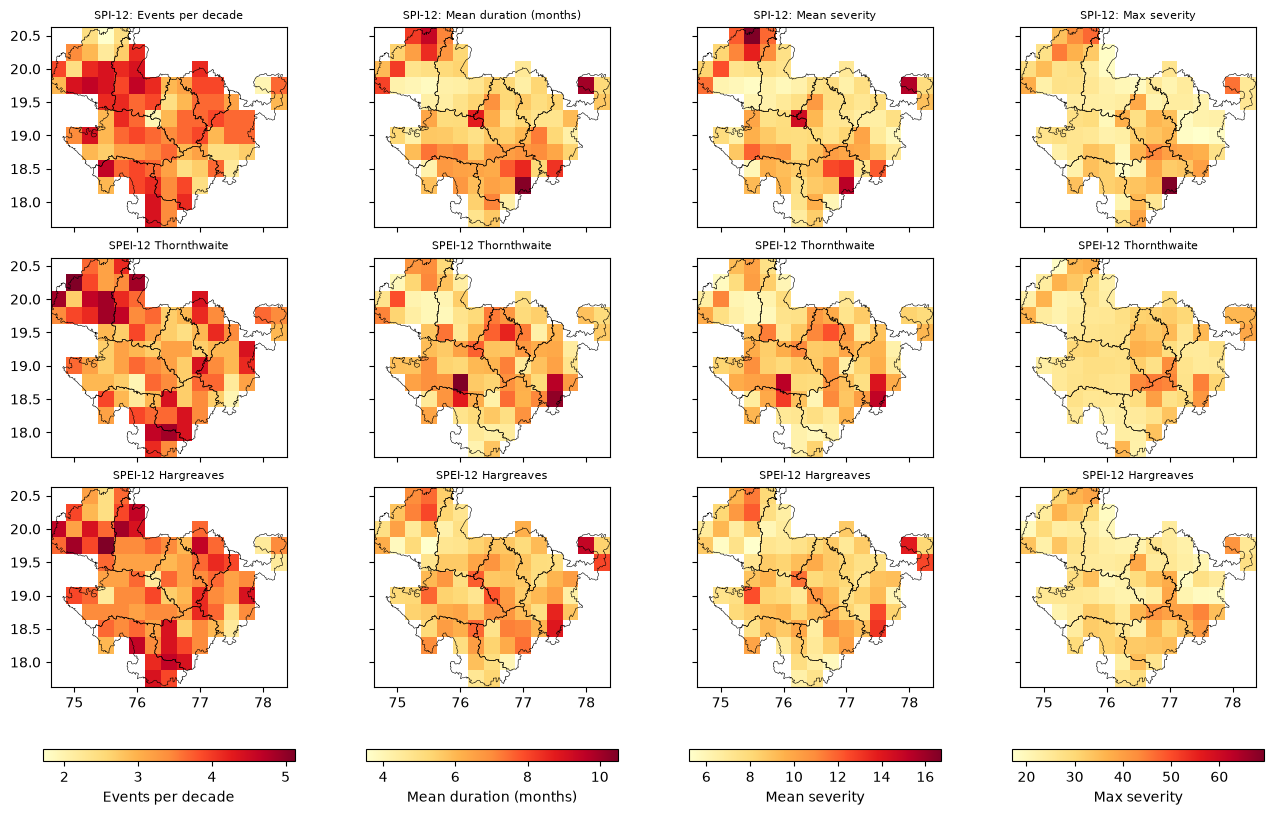

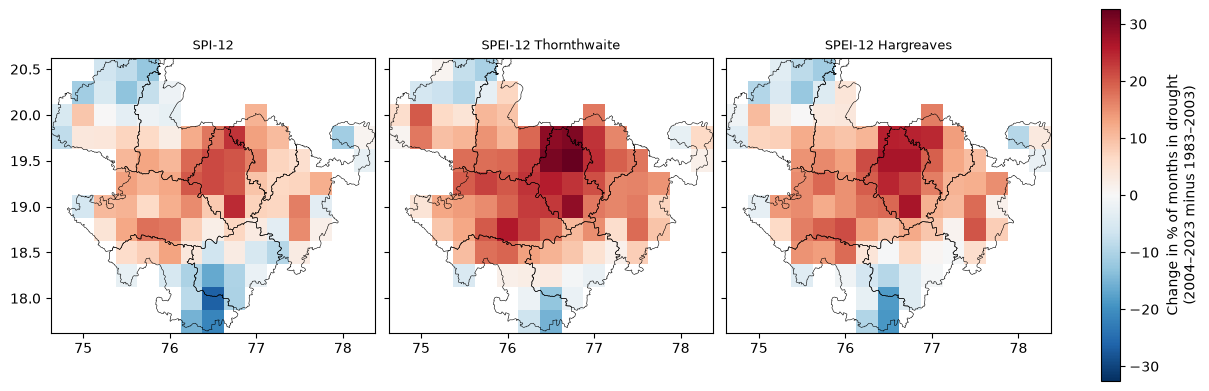

In [6]:
import geopandas as gpd
import matplotlib.pyplot as plt

districts = gpd.read_file("../data/shapefiles/marathwada_districts.gpkg")
titles = {"spi": "SPI-12", "spei_th": "SPEI-12 Thornthwaite", "spei_hg": "SPEI-12 Hargreaves"}
cols = ["events_per_decade", "mean_duration", "mean_severity", "max_severity"]
labels = ["Events per decade", "Mean duration (months)", "Mean severity", "Max severity"]

fig, axes = plt.subplots(3, 4, figsize=(13, 8), sharex=True, sharey=True, layout="constrained")
for j, (c, lab) in enumerate(zip(cols, labels)):
    data = stats.sel(scale=12, stat=c)
    vmin = float(data.to_array().min())
    vmax = float(data.to_array().max())
    for i, v in enumerate(names):
        ax = axes[i, j]
        im = data[v].plot(ax=ax, vmin=vmin, vmax=vmax, cmap="YlOrRd", add_colorbar=False)
        districts.boundary.plot(ax=ax, color="k", lw=0.4)
        ax.set_title(f"{titles[v]}: {lab}" if i == 0 else titles[v], fontsize=8)
        ax.set_xlabel("")
        ax.set_ylabel("")
    fig.colorbar(im, ax=axes[:, j], orientation="horizontal", shrink=0.8, label=lab)
fig.savefig("../outputs/figures/fig06_drought_characteristics_12m.png", dpi=300)

fig, axes = plt.subplots(1, 3, figsize=(12, 3.8), sharey=True, layout="constrained")
lim = float(abs(shift.sel(scale=12).to_array()).max())
for ax, v in zip(axes, names):
    im = shift[v].sel(scale=12).plot(ax=ax, vmin=-lim, vmax=lim, cmap="RdBu_r", add_colorbar=False)
    districts.boundary.plot(ax=ax, color="k", lw=0.4)
    ax.set_title(titles[v], fontsize=9)
    ax.set_xlabel("")
    ax.set_ylabel("")
fig.colorbar(im, ax=axes, label="Change in % of months in drought\n(2004–2023 minus 1983–2003)")
fig.savefig("../outputs/figures/fig07_drought_time_shift_12m.png", dpi=300)